# Polity match gaps
Share of individuals with an active life matched to at least one life-stage polity, per century.

In [1]:
import random
import tempfile
import numpy as np
import polars as pl
import duckdb
import matplotlib.pyplot as plt
from style import *

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DB_PATH = '../../data/cultura/cultura_database_V4.duckdb'

BORN_AFTER_CUTOFF = 1995
BUCKET_YEARS = 100
BUCKET_MIN_INDIVIDUALS = 50
YEAR_RANGE = (-3000, 2025)

apply_style()

## Connect

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='6GB'; SET threads=4; SET temp_directory='{tempfile.mkdtemp()}';")

## Load data
### Individuals

In [3]:
con.sql('''
    CREATE OR REPLACE TEMP TABLE person AS
    SELECT
        entity.qid                AS qid,
        birth_date.year           AS birth_year,
        death_date.year           AS death_year,
        start_of_active_life.year AS window_start,
        birth_date.year IS NOT NULL OR birth_date.coarse_label IS NOT NULL OR death_date.coarse_label IS NOT NULL AS dated,  -- a century-level date counts (step 10)
        len(pre_active_life_polity) > 0
            OR len(active_life_polity) > 0
            OR len(post_active_life_polity) > 0 AS has_polity_match
    FROM individual_enriched
''')

n_individuals = con.sql('SELECT COUNT(*) FROM person').fetchone()[0]
assert n_individuals == con.sql('SELECT COUNT(DISTINCT qid) FROM person').fetchone()[0]
print(f'individuals: {n_individuals:,}')
con.sql('SELECT * FROM person USING SAMPLE reservoir(5 ROWS) REPEATABLE (42)').pl()

individuals: 13,002,840


qid,birth_year,death_year,window_start,dated,has_polity_match
str,i64,i64,i64,bool,bool
"""Q100138356""",1844,1892,1877,true,true
"""Q100149237""",1964,null,null,true,false
"""Q100384950""",null,null,null,false,false
"""Q100406234""",null,null,null,false,false
"""Q100423432""",null,null,null,false,false


### Cohort (living born after 1995 excluded)

In [4]:
con.sql('''
    CREATE OR REPLACE TEMP TABLE cohort AS
    SELECT
        *,
        window_start IS NOT NULL AS has_window
    FROM person
    WHERE birth_year IS NULL
       OR birth_year <= $born_after_cutoff
       OR death_year IS NOT NULL
''', params={'born_after_cutoff': BORN_AFTER_CUTOFF})

n_cohort = con.sql('SELECT COUNT(*) FROM cohort').fetchone()[0]
print(f'before filter: {n_individuals:,}')
print(f'after filter:  {n_cohort:,}')
print(f'excluded:      {n_individuals - n_cohort:,}')

before filter: 13,002,840
after filter:  12,679,900
excluded:      322,940


### Active-life and polity counts per bucket

In [5]:
bucket_counts = con.sql('''
    SELECT
        CAST(FLOOR(window_start / $bucket_years) * $bucket_years AS INTEGER) AS bucket,
        COUNT(*)                                  AS individuals,
        COUNT(*) FILTER (WHERE has_polity_match)  AS with_polity,
        COUNT(*) FILTER (WHERE dated) AS with_dates
    FROM cohort
    WHERE has_window
      AND window_start BETWEEN $year_min AND $year_max
    GROUP BY bucket
    ORDER BY bucket
''', params={'bucket_years': BUCKET_YEARS, 'year_min': YEAR_RANGE[0], 'year_max': YEAR_RANGE[1]}).pl()

assert bucket_counts.filter(pl.col('with_polity') > pl.col('with_dates')).is_empty()
con.close()
print('shape:', bucket_counts.shape)
bucket_counts.head()

shape: (51, 4)


bucket,individuals,with_polity,with_dates
i32,i64,i64,i64
-3000,14,6,14
-2900,4,2,4
-2800,3,1,2
-2700,9,5,9
-2600,16,8,16


## Preprocessing

### Share with a polity per century

In [6]:
last_complete_bucket = (YEAR_RANGE[1] + 1) // BUCKET_YEARS * BUCKET_YEARS - BUCKET_YEARS
print('centuries before filter:', bucket_counts.height)

share_with_polity = (
    bucket_counts
    .filter(pl.col('bucket') <= last_complete_bucket)
    .filter(pl.col('individuals') >= BUCKET_MIN_INDIVIDUALS)
    .with_columns((pl.col('with_polity') / pl.col('individuals') * 100).round(1).alias('pct_with_polity'))
    .sort('bucket')
)
print('centuries after filter: ', share_with_polity.height)

assert share_with_polity['pct_with_polity'].is_between(0, 100).all()
share_with_polity.tail()

centuries before filter: 51


centuries after filter:  30


bucket,individuals,with_polity,with_dates,pct_with_polity
i32,i64,i64,i64,f64
1500,88301,47365,85713,53.6
1600,165661,83993,163266,50.7
1700,256193,131237,252907,51.2
1800,816124,526699,809169,64.5
1900,3111948,2311572,3088020,74.3


## Figures

### Figure S5: Share of individuals with a polity match per century

#### Data plotted

In [7]:
print('shape:', share_with_polity.shape)
share_with_polity

shape: (30, 5)


bucket,individuals,with_polity,with_dates,pct_with_polity
i32,i64,i64,i64,f64
-1400,59,28,57,47.5
-900,83,43,78,51.8
-800,122,76,119,62.3
-700,212,124,204,58.5
-600,384,242,372,63.0
…,…,…,…,…
1500,88301,47365,85713,53.6
1600,165661,83993,163266,50.7
1700,256193,131237,252907,51.2


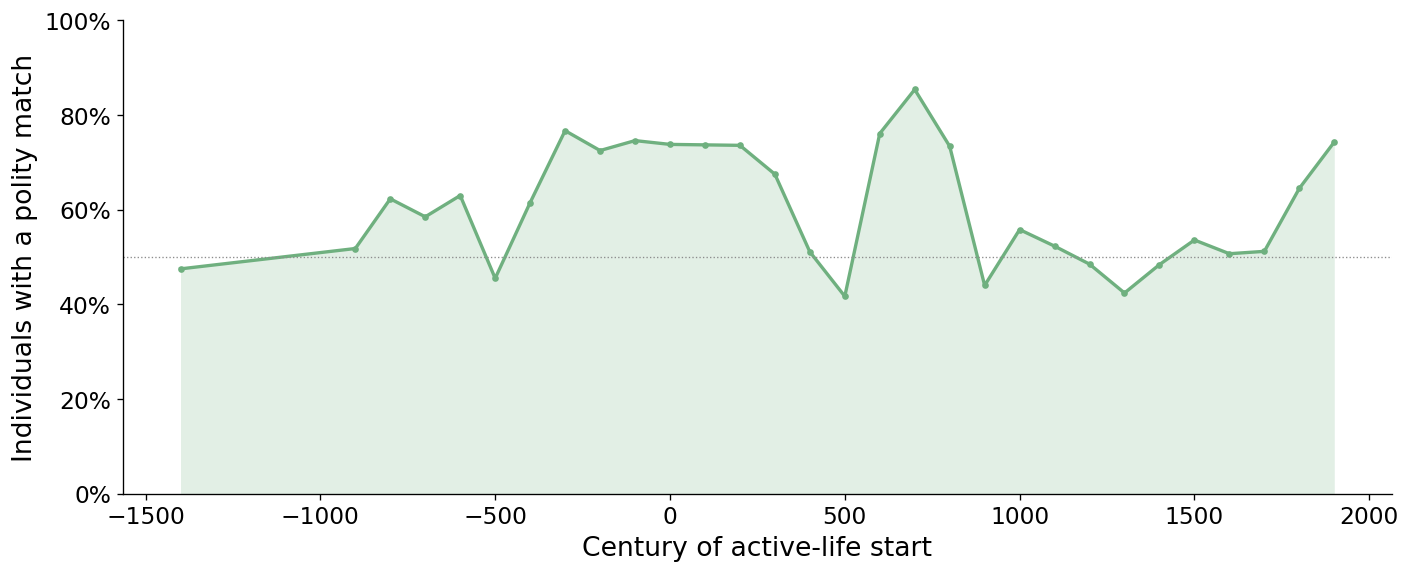

In [8]:
buckets = share_with_polity['bucket']
pct = share_with_polity['pct_with_polity']

fig, ax = plt.subplots()
ax.fill_between(buckets, 0, pct, color=POLITY_MATCH_COLORS['with_polity'], alpha=BAND_ALPHA, lw=0)
ax.plot(buckets, pct, color=POLITY_MATCH_COLORS['with_polity'], marker='o', ms=3)
ax.axhline(50, **REFERENCE_LINE)
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(PERCENT)
ax.set_xticks(range(buckets.min() // 500 * 500, 2001, 500))
ax.set_xlabel('Century of active-life start')
ax.set_ylabel('Individuals with a polity match')
plt.tight_layout()
plt.show()